# 05 — Model Training (Insurance Claim Cost)

## Objective
Predict pure premium (expected claim cost per policy) and compare
approaches on one scoreboard against two baselines.

## Candidates
1. Tweedie GLM (log link, L2 penalty): the actuarial standard
2. LightGBM with the Tweedie objective
3. Two-part LightGBM: P(claim) x E[severity ratio | claim] x IDV

## Baselines
- Current premium, scaled to the training mean loss
- IDV only, scaled: the fair floor, because premium is mostly IDV
- Reference (not a model): the generator's TRUE P(claim) x our severity,
  which shows how much frequency signal is left to find

## Metrics
- Normalised Gini (primary): rank quality, handles the 63% zeros
- Tweedie deviance at a fixed power (calibration of the amount)
- Balance = sum(predicted) / sum(actual)
- Capture@20%: share of total claim cost in the riskiest 20% of policies

## Rules
- Tweedie power chosen by cross-validated Gini, not by deviance
- Primary model fixed in advance: Tweedie LightGBM. The others are
  comparisons, so we do not pick a winner by peeking at the test set.
- Paired bootstrap on the test set to say which gaps are real
- Models train on claim amounts in units of ₹1,000 (Y_SCALE)

In [1]:
import pandas as pd
import numpy as np
import json
import pickle
import os
import warnings
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.linear_model import TweedieRegressor
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_tweedie_deviance, mean_gamma_deviance, roc_auc_score
)
warnings.filterwarnings("ignore")

PROCESSED = "../data/processed"
SEED      = 42
Y_SCALE   = 1000.0

spec     = json.load(open(f"{PROCESSED}/feature_spec.json"))
FEATURES = spec["feature_cols"]

df = (pd.read_csv(f"{PROCESSED}/modeling_data.csv")
      .merge(pd.read_csv(f"{PROCESSED}/baseline_premium.csv"),
             on="policy_id", validate="1:1")
      .merge(pd.read_csv(f"{PROCESSED}/oracle_claim_prob.csv"),
             on="policy_id", validate="1:1"))

# NB04 did not carry the artifact flags: pull them from the cleaned tables
link = pd.read_csv(f"{PROCESSED}/policies_clean.csv",
                   usecols=["policy_id", "policyholder_id"])
veh  = pd.read_csv(f"{PROCESSED}/vehicles_clean.csv",
                   usecols=["policyholder_id", "vehicle_make", "idv",
                            "vehicle_age_missing"])
ph   = pd.read_csv(f"{PROCESSED}/policyholders_clean.csv",
                   usecols=["policyholder_id", "ncb_missing"])
df = (df.merge(link, on="policy_id", validate="1:1")
        .merge(veh[["policyholder_id", "vehicle_age_missing"]],
               on="policyholder_id", validate="1:1")
        .merge(ph, on="policyholder_id", validate="1:1"))

assert len(df) == 97_978 and df["policy_id"].is_unique
assert all(c in df.columns for c in FEATURES)
assert df[FEATURES].isnull().sum().sum() == 0
bad = [c for c in FEATURES
       if c in spec["forbidden"] or c.startswith("claim_")]
assert not bad, f"forbidden columns in features: {bad}"

print("Loaded and merged ✅")
print(f"  rows {len(df):,} | features {len(FEATURES)} | "
      f"claim rate {df['has_claim'].mean()*100:.2f}%")
print("  leakage assertion passed (premium, claim_prob, flags not in FEATURES)")

# ── The IDV hypothesis test from last time ────────────────────
veh["idv_vs_make"] = veh["idv"] / veh.groupby("vehicle_make")["idv"].transform("median")
r = veh.groupby("vehicle_age_missing")["idv_vs_make"].agg(["median", "count"])
print("\nIDV relative to the make's median IDV, by missing vehicle age:")
print(r.round(3).to_string())
supported = r.loc[1, "median"] > 1.25   # midway between 1.0 (no effect) and ~1.45
print("Hypothesis (missing age => IDV priced as a new car):",
      "SUPPORTED" if supported else "NOT supported, look for another cause")

# ── Metrics ───────────────────────────────────────────────────
def lorenz(actual, score):
    """Cumulative share of loss when policies are ranked low to high score.
    Tied scores are merged into one segment, so ties get the expected
    value under random ordering instead of depending on row order."""
    a = np.asarray(actual, float)
    s = np.asarray(score, float)
    g = pd.DataFrame({"a": a, "s": s}).groupby("s", sort=True)["a"].agg(["sum", "size"])
    x = np.concatenate([[0.0], g["size"].to_numpy().cumsum() / len(a)])
    y = np.concatenate([[0.0], g["sum"].to_numpy().cumsum() / a.sum()])
    return x, y

def gini(actual, score):
    x, y = lorenz(actual, score)
    return 1 - 2 * np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2)

def norm_gini(actual, score):
    return gini(actual, score) / gini(actual, actual)

def dev(y, mu, p):
    return mean_tweedie_deviance(np.asarray(y) / Y_SCALE,
                                 np.maximum(np.asarray(mu), 1e-6) / Y_SCALE,
                                 power=p)

def capture(actual, score, top=0.2, seed=0):
    a = np.asarray(actual, float)
    s = np.asarray(score, float)
    tie = np.random.default_rng(seed).random(len(s))
    order = np.lexsort((tie, -s))          # score descending, random ties
    return a[order[: int(len(a) * top)]].sum() / a.sum()

# Sanity: random ~ 0, perfect = 1, reversed < 0
y_all = df["claim_amount"].to_numpy()
rng = np.random.default_rng(0)
print(f"\nGini sanity: random {norm_gini(y_all, rng.random(len(y_all))):+.4f} | "
      f"perfect {norm_gini(y_all, y_all):+.4f} | reversed {norm_gini(y_all, -y_all):+.4f}")

Loaded and merged ✅
  rows 97,978 | features 66 | claim rate 36.49%
  leakage assertion passed (premium, claim_prob, flags not in FEATURES)

IDV relative to the make's median IDV, by missing vehicle age:
                     median  count
vehicle_age_missing               
0                     0.992  95999
1                     1.552   1979
Hypothesis (missing age => IDV priced as a new car): SUPPORTED

Gini sanity: random +0.0078 | perfect +1.0000 | reversed -1.0000


In [2]:
print("STEP 1 — SPLIT AND BASELINES\n")

tr_idx, te_idx = train_test_split(
    np.arange(len(df)), test_size=0.2, random_state=SEED,
    stratify=df["has_claim"])
train = df.iloc[tr_idx].reset_index(drop=True)
test  = df.iloc[te_idx].reset_index(drop=True)

X_tr = train[FEATURES].to_numpy(float); y_tr = train["claim_amount"].to_numpy(float)
X_te = test[FEATURES].to_numpy(float);  y_te = test["claim_amount"].to_numpy(float)
f_tr = train["has_claim"].to_numpy(int)
f_te = test["has_claim"].to_numpy(int)
idv_te = test["idv"].to_numpy(float)

# One inner split reused for every early-stopping probe; one set of CV folds
ia, ib = train_test_split(np.arange(len(train)), test_size=0.15,
                          random_state=SEED, stratify=f_tr)
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, f_tr))

print(f"{'Set':<6}{'Rows':>8}{'Claim rate':>12}{'Total cost':>14}"
      f"{'Largest claim':>16}{'Top-10 share':>14}")
for name, d in [("train", train), ("test", test)]:
    a = np.sort(d["claim_amount"].to_numpy())[::-1]
    print(f"{name:<6}{len(d):>8,}{d['has_claim'].mean()*100:>11.2f}%"
          f"{a.sum()/1e6:>12,.1f}M{a[0]/1e6:>14.2f}M{a[:10].sum()/a.sum()*100:>13.1f}%")
print("(a few huge claims make test-set Gini noisy: hence the bootstrap in Cell 7)")

P_REF  = 1.67
k_prem = y_tr.sum() / train["total_premium"].sum()
k_idv  = y_tr.sum() / train["idv"].sum()
BASE = {
    "Premium (scaled)":  k_prem * test["total_premium"].to_numpy(),
    "IDV only (scaled)": k_idv * idv_te,
}
const = np.full(len(y_te), y_tr.mean())

print(f"\nBaselines on the test set (deviance at p={P_REF}, ₹1,000 units):")
print(f"  {'Baseline':<20}{'Norm Gini':>10}{'Deviance':>10}{'Freq AUC':>10}")
print(f"  {'Constant (mean)':<20}{norm_gini(y_te, const):>10.4f}"
      f"{dev(y_te, const, P_REF):>10.3f}{0.5:>10.4f}")
for nm, s in BASE.items():
    print(f"  {nm:<20}{norm_gini(y_te, s):>10.4f}{dev(y_te, s, P_REF):>10.3f}"
          f"{roc_auc_score(f_te, s):>10.4f}")
auc_oracle = roc_auc_score(f_te, test["claim_prob"])
print(f"  {'True P(claim)':<20}{'':>10}{'':>10}{auc_oracle:>10.4f}"
      f"   <- best frequency AUC any model can reach")

g_full = norm_gini(df["claim_amount"], df["total_premium"])
print(f"\nPremium normalised Gini, all rows, tie-aware: {g_full:.4f} "
      f"(EDA printed 0.6800 with row-order ties)")

STEP 1 — SPLIT AND BASELINES

Set       Rows  Claim rate    Total cost   Largest claim  Top-10 share
train   78,382      36.49%     6,178.5M         10.70M          1.1%
test    19,596      36.49%     1,639.3M          9.37M          3.8%
(a few huge claims make test-set Gini noisy: hence the bootstrap in Cell 7)

Baselines on the test set (deviance at p=1.67, ₹1,000 units):
  Baseline             Norm Gini  Deviance  Freq AUC
  Constant (mean)         0.0000    24.951    0.5000
  Premium (scaled)        0.6913    19.166    0.5735
  IDV only (scaled)       0.6727    19.411    0.4996
  True P(claim)                               0.6786   <- best frequency AUC any model can reach

Premium normalised Gini, all rows, tie-aware: 0.6800 (EDA printed 0.6800 with row-order ties)


STEP 2 — HOW MANY TREES, THEN WHICH TWEEDIE POWER

Trees from early stopping at p=1.67: 300 (reused for every p below, an approximation)
  p=1.2   done
  p=1.4   done
  p=1.55  done
  p=1.67  done
  p=1.8   done
  p=1.9   done

  Power  Gini mean    ± SE  Gini pooled  Dev@1.67  Balance
   1.20     0.7394  0.0035       0.7394    17.052    0.973
   1.40     0.7400  0.0037       0.7400    17.005    0.958
   1.55     0.7400  0.0036       0.7400    16.994    0.948
   1.67     0.7401  0.0038       0.7402    16.995    0.938  <- best
   1.80     0.7400  0.0038       0.7400    17.014    0.927
   1.90     0.7398  0.0039       0.7399    17.044    0.918

Powers within one SE of the best: [1.2, 1.4, 1.55, 1.67, 1.8, 1.9]
Chosen p = 1.67  (EDA estimate kept: CV cannot separate it from the best)


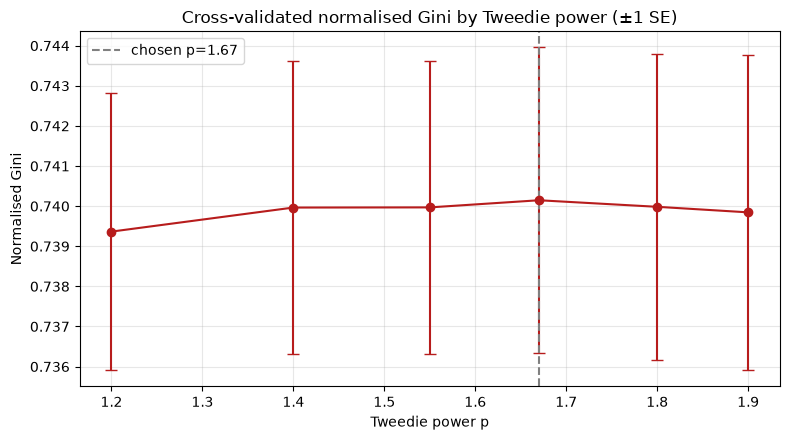

In [3]:
print("STEP 2 — HOW MANY TREES, THEN WHICH TWEEDIE POWER\n")

GBM_BASE = dict(learning_rate=0.03, num_leaves=15, min_child_samples=200,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                reg_lambda=5.0, random_state=SEED, n_jobs=-1, verbose=-1)

# Trees: one early-stopping probe on an inner split, then fixed for the CV
probe = LGBMRegressor(objective="tweedie", tweedie_variance_power=P_REF,
                      n_estimators=3000, **GBM_BASE)
probe.fit(X_tr[ia], y_tr[ia] / Y_SCALE,
          eval_set=[(X_tr[ib], y_tr[ib] / Y_SCALE)],
          callbacks=[lgb.early_stopping(100, verbose=False)])
N_TREES = int(max(100, probe.best_iteration_))
print(f"Trees from early stopping at p={P_REF}: {N_TREES} "
      f"(reused for every p below, an approximation)")

P_GRID  = [1.2, 1.4, 1.55, 1.67, 1.8, 1.9]
cv_rows = []
for p in P_GRID:
    oof, fold_g = np.zeros(len(train)), []
    for tri, vai in folds:
        m = LGBMRegressor(objective="tweedie", tweedie_variance_power=p,
                          n_estimators=N_TREES, **GBM_BASE)
        m.fit(X_tr[tri], y_tr[tri] / Y_SCALE)
        pred = m.predict(X_tr[vai]) * Y_SCALE
        oof[vai] = pred
        fold_g.append(norm_gini(y_tr[vai], pred))
    cv_rows.append(dict(
        p=p,
        gini_mean=np.mean(fold_g),
        gini_se=np.std(fold_g, ddof=1) / np.sqrt(len(fold_g)),
        gini_pooled=norm_gini(y_tr, oof),
        dev_ref=dev(y_tr, oof, P_REF),
        balance=oof.sum() / y_tr.sum()))
    print(f"  p={p:<5} done")

cv   = pd.DataFrame(cv_rows)
best = cv.loc[cv["gini_mean"].idxmax()]
close = cv[cv["gini_mean"] >= best["gini_mean"] - best["gini_se"]]
P_FINAL = P_REF if np.isclose(close["p"], P_REF).any() else float(best["p"])

print(f"\n{'Power':>7}{'Gini mean':>11}{'± SE':>8}{'Gini pooled':>13}"
      f"{'Dev@1.67':>10}{'Balance':>9}")
for _, r in cv.iterrows():
    tag = "  <- best" if np.isclose(r["p"], best["p"]) else ""
    print(f"{r['p']:>7.2f}{r['gini_mean']:>11.4f}{r['gini_se']:>8.4f}"
          f"{r['gini_pooled']:>13.4f}{r['dev_ref']:>10.3f}{r['balance']:>9.3f}{tag}")
print(f"\nPowers within one SE of the best: {close['p'].tolist()}")
print(f"Chosen p = {P_FINAL}  "
      f"({'EDA estimate kept: CV cannot separate it from the best' if P_FINAL == P_REF else 'CV clearly prefers a different power'})")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(cv["p"], cv["gini_mean"], yerr=cv["gini_se"], fmt="o-",
            color="#B71C1C", capsize=4)
ax.axvline(P_FINAL, color="gray", linestyle="--", label=f"chosen p={P_FINAL}")
ax.set_title("Cross-validated normalised Gini by Tweedie power (±1 SE)")
ax.set_xlabel("Tweedie power p")
ax.set_ylabel("Normalised Gini")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PROCESSED}/model_01_tweedie_power.png", dpi=130, bbox_inches="tight")
plt.show()

In [4]:
print("STEP 3 — TWEEDIE GLM (log link, L2 penalty)\n")

GLM_ALPHAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]
glm_rows = []
for a in GLM_ALPHAS:
    oof, worst_iter = np.zeros(len(train)), 0
    for tri, vai in folds:
        pipe = make_pipeline(
            StandardScaler(),
            TweedieRegressor(power=P_FINAL, alpha=a, link="log", max_iter=2000))
        pipe.fit(X_tr[tri], y_tr[tri] / Y_SCALE)
        oof[vai] = pipe.predict(X_tr[vai]) * Y_SCALE
        worst_iter = max(worst_iter, int(np.max(pipe[-1].n_iter_)))
    glm_rows.append(dict(alpha=a, deviance=dev(y_tr, oof, P_FINAL),
                         gini=norm_gini(y_tr, oof), iters=worst_iter))

glm_cv = pd.DataFrame(glm_rows)
ALPHA  = float(glm_cv.loc[glm_cv["deviance"].idxmin(), "alpha"])
print(f"CV at fixed power p={P_FINAL} (deviance IS comparable across alpha here)")
print(f"{'alpha':>8}{'Deviance':>10}{'Norm Gini':>11}{'Max iters':>11}")
for _, r in glm_cv.iterrows():
    tag = "  <- chosen" if r["alpha"] == ALPHA else ""
    print(f"{r['alpha']:>8g}{r['deviance']:>10.3f}{r['gini']:>11.4f}"
          f"{int(r['iters']):>11}{tag}")
if (glm_cv["iters"] >= 2000).any():
    print("⚠️ some fits hit max_iter: coefficients may not be converged")

glm = make_pipeline(
    StandardScaler(),
    TweedieRegressor(power=P_FINAL, alpha=ALPHA, link="log", max_iter=2000))
glm.fit(X_tr, y_tr / Y_SCALE)
pred_glm = glm.predict(X_te) * Y_SCALE

coef = pd.Series(glm[-1].coef_, index=FEATURES)
top  = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
print("\nLargest effects (multiplicative on expected cost per +1 SD of the feature):")
for f, c in top.items():
    print(f"  {f:<32} x{np.exp(c):>6.3f}")
print("Rough guide only: one-hot columns within a category are collinear and")
print("penalised, so read their effects relative to each other.")

STEP 3 — TWEEDIE GLM (log link, L2 penalty)

CV at fixed power p=1.67 (deviance IS comparable across alpha here)
   alpha  Deviance  Norm Gini  Max iters
   0.001    16.979     0.7400         35  <- chosen
    0.01    16.979     0.7400         35
     0.1    16.987     0.7398         29
       1    17.093     0.7375         17
      10    18.305     0.7300         10

Largest effects (multiplicative on expected cost per +1 SD of the feature):
  log_idv                          x 2.254
  has_od_cover                     x 1.293
  policy_type_third_party_only     x 0.773
  policy_type_comprehensive        x 1.224
  prior_claims_count               x 1.169
  vehicle_type_taxi                x 1.143
  vehicle_type_two_wheeler         x 0.885
  vehicle_type_commercial_vehicle  x 1.120
  ncb_percentage                   x 0.893
  is_young_driver                  x 1.119
  policy_type_standalone_od        x 1.101
  vehicle_segment_luxury           x 1.100
Rough guide only: one-hot columns wit

In [5]:
print("STEP 4 — LIGHTGBM TWEEDIE AND THE TWO-PART MODEL\n")

# ── Tweedie LightGBM at the chosen power ──────────────────────
gbm = LGBMRegressor(objective="tweedie", tweedie_variance_power=P_FINAL,
                    n_estimators=N_TREES, **GBM_BASE)
gbm.fit(X_tr, y_tr / Y_SCALE)
pred_gbm = gbm.predict(X_te) * Y_SCALE

imp = pd.Series(gbm.booster_.feature_importance(importance_type="gain"),
                index=FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False)
print("Tweedie LightGBM, top 12 features by share of gain:")
for f, v in imp.head(12).items():
    print(f"  {f:<32} {v*100:5.1f}%  {'█' * int(v * 100)}")
print(f"  policy_start_quarter rank: "
      f"{list(imp.index).index('policy_start_quarter') + 1} of {len(imp)}")

# ── Part 1: frequency ─────────────────────────────────────────
clf_probe = LGBMClassifier(objective="binary", n_estimators=3000, **GBM_BASE)
clf_probe.fit(X_tr[ia], f_tr[ia], eval_set=[(X_tr[ib], f_tr[ib])],
              eval_metric="binary_logloss",
              callbacks=[lgb.early_stopping(100, verbose=False)])
N_FREQ = int(max(100, clf_probe.best_iteration_))
clf = LGBMClassifier(objective="binary", n_estimators=N_FREQ, **GBM_BASE)
clf.fit(X_tr, f_tr)
p_claim_te = clf.predict_proba(X_te)[:, 1]

# ── Part 2: severity as a ratio of IDV, claimants only ────────
c_mask = f_tr == 1
Xc = X_tr[c_mask]
rc = train.loc[c_mask, "severity_ratio"].to_numpy(float)
assert np.isfinite(rc).all() and (rc > 0).all()

ca, cb = train_test_split(np.arange(len(Xc)), test_size=0.15, random_state=SEED)
SEV_BASE = {**GBM_BASE, "min_child_samples": 100}
sev_probe = LGBMRegressor(objective="gamma", n_estimators=3000, **SEV_BASE)
sev_probe.fit(Xc[ca], rc[ca], eval_set=[(Xc[cb], rc[cb])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
N_SEV = int(max(100, sev_probe.best_iteration_))
sev = LGBMRegressor(objective="gamma", n_estimators=N_SEV, **SEV_BASE)
sev.fit(Xc, rc)
sev_ratio_te = sev.predict(X_te)

pred_two   = p_claim_te * sev_ratio_te * idv_te
oracle_ref = test["claim_prob"].to_numpy() * sev_ratio_te * idv_te

# ── Diagnostics for each part ─────────────────────────────────
print(f"\nTrees: tweedie {N_TREES} | frequency {N_FREQ} | severity {N_SEV}")
print("\nFrequency (has_claim), test AUC:")
print(f"  frequency model : {roc_auc_score(f_te, p_claim_te):.4f}")
print(f"  premium         : {roc_auc_score(f_te, BASE['Premium (scaled)']):.4f}")
print(f"  IDV only        : {roc_auc_score(f_te, BASE['IDV only (scaled)']):.4f}")
print(f"  true P(claim)   : {auc_oracle:.4f}   <- ceiling")

tc = f_te == 1
r_te, r_hat = test.loc[tc, "severity_ratio"].to_numpy(float), sev_ratio_te[tc]
d2 = 1 - mean_gamma_deviance(r_te, r_hat) / mean_gamma_deviance(r_te, np.full_like(r_te, rc.mean()))
sp = pd.Series(r_hat).corr(pd.Series(r_te), method="spearman")
print(f"\nSeverity ratio on test claimants (n={tc.sum():,}):")
print(f"  gamma deviance explained vs constant : {d2:.4f}")
print(f"  Spearman(predicted, actual)          : {sp:.4f}")
print("  Claim type is unknown at quote time, so severity is a mixture over")
print("  theft / fire / own damage. Expect modest explained deviance.")

STEP 4 — LIGHTGBM TWEEDIE AND THE TWO-PART MODEL

Tweedie LightGBM, top 12 features by share of gain:
  log_idv                           54.5%  ██████████████████████████████████████████████████████
  has_od_cover                      12.1%  ████████████
  vehicle_segment_luxury            11.8%  ███████████
  policy_type_third_party_only       3.6%  ███
  vehicle_segment_economy            2.3%  ██
  prior_claims_count                 2.1%  ██
  engine_cc                          1.3%  █
  ncb_percentage                     1.1%  █
  age                                1.1%  █
  vehicle_segment_mid                0.9%  
  vehicle_age_years                  0.8%  
  vehicle_type_taxi                  0.8%  
  policy_start_quarter rank: 34 of 66

Trees: tweedie 300 | frequency 223 | severity 100

Frequency (has_claim), test AUC:
  frequency model : 0.6755
  premium         : 0.5735
  IDV only        : 0.4996
  true P(claim)   : 0.6786   <- ceiling

Severity ratio on test claimants (n=7,

STEP 5 — SCOREBOARD ON THE TEST SET

Tweedie deviance at p=1.67; primary model fixed in advance: Tweedie LightGBM

Model                                  Norm Gini  Deviance  Balance  Capture@20%
Premium (scaled)                          0.6913    19.166    0.942        69.6%
IDV only (scaled)                         0.6727    19.411    0.940        69.4%
Tweedie GLM                               0.7443    17.291    0.973        73.2%
Tweedie LightGBM                          0.7428    17.361    0.893        72.8%  *
Two-part LightGBM                         0.7449    17.299    0.899        73.0%
Ref: true P(claim) x model severity       0.7469    17.247    0.899        73.1%

Paired bootstrap of normalised Gini differences (300 resamples):
  Comparison                                        Mean          95% interval
  Tweedie LightGBM  vs  Premium (scaled)         +0.0511   [+0.0436, +0.0581]  real
  Tweedie LightGBM  vs  IDV only (scaled)        +0.0701   [+0.0612, +0.0781]  real
  

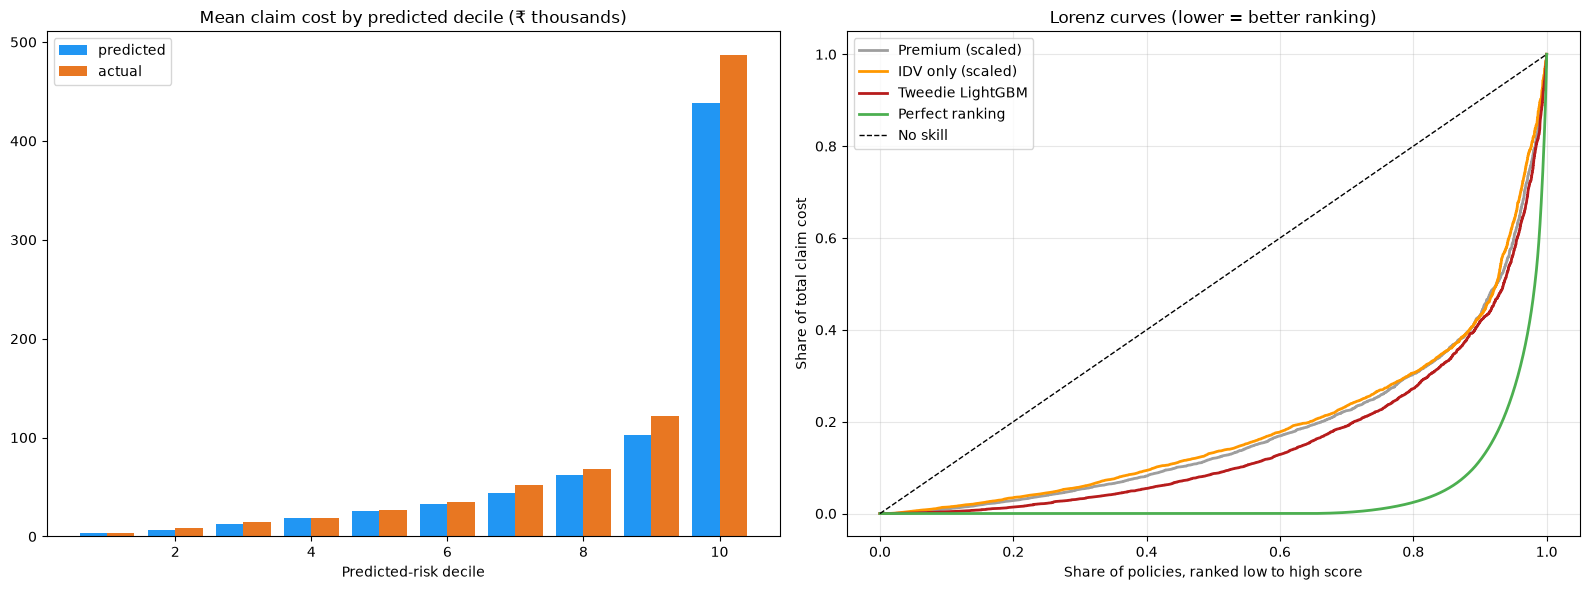

In [6]:
print("STEP 5 — SCOREBOARD ON THE TEST SET\n")

MODELS = {
    "Premium (scaled)":  BASE["Premium (scaled)"],
    "IDV only (scaled)": BASE["IDV only (scaled)"],
    "Tweedie GLM":       pred_glm,
    "Tweedie LightGBM":  pred_gbm,
    "Two-part LightGBM": pred_two,
}
REF_NAME = "Ref: true P(claim) x model severity"
ALL = {**MODELS, REF_NAME: oracle_ref}

score = pd.DataFrame([
    dict(model=nm,
         norm_gini=norm_gini(y_te, s),
         deviance=dev(y_te, s, P_FINAL),
         balance=s.sum() / y_te.sum(),
         capture20=capture(y_te, s))
    for nm, s in ALL.items()])

print(f"Tweedie deviance at p={P_FINAL}; primary model fixed in advance: Tweedie LightGBM\n")
print(f"{'Model':<38}{'Norm Gini':>10}{'Deviance':>10}{'Balance':>9}{'Capture@20%':>13}")
for _, r in score.iterrows():
    mark = "  *" if r["model"] == "Tweedie LightGBM" else ""
    print(f"{r['model']:<38}{r['norm_gini']:>10.4f}{r['deviance']:>10.3f}"
          f"{r['balance']:>9.3f}{r['capture20']*100:>12.1f}%{mark}")

# ── Paired bootstrap on the test set ──────────────────────────
rng, B, n = np.random.default_rng(SEED), 300, len(y_te)
boot = {nm: [] for nm in MODELS}
for _ in range(B):
    i = rng.integers(0, n, n)
    a = y_te[i]
    den = gini(a, a)
    for nm, s in MODELS.items():
        boot[nm].append(gini(a, s[i]) / den)
boot = {k: np.array(v) for k, v in boot.items()}

print(f"\nPaired bootstrap of normalised Gini differences ({B} resamples):")
print(f"  {'Comparison':<46}{'Mean':>8}{'95% interval':>22}")
pairs = [("Tweedie LightGBM", "Premium (scaled)"),
         ("Tweedie LightGBM", "IDV only (scaled)"),
         ("Tweedie LightGBM", "Tweedie GLM"),
         ("Two-part LightGBM", "Tweedie LightGBM")]
BOOT_OUT = {}
for a_, b_ in pairs:
    d = boot[a_] - boot[b_]
    lo, hi = np.percentile(d, [2.5, 97.5])
    verdict = "real" if (lo > 0 or hi < 0) else "within noise"
    BOOT_OUT[f"{a_} - {b_}"] = dict(mean=float(d.mean()), lo=float(lo), hi=float(hi))
    print(f"  {a_ + '  vs  ' + b_:<46}{d.mean():>+8.4f}   [{lo:+.4f}, {hi:+.4f}]  {verdict}")
print("Only test-set sampling is resampled: training variance is not included.")

# ── Lift by predicted decile, primary model ───────────────────
dec = pd.DataFrame({"pred": pred_gbm, "act": y_te})
dec["decile"] = pd.qcut(dec["pred"].rank(method="first"), 10, labels=False) + 1
lift = dec.groupby("decile").agg(policies=("act", "size"),
                                 predicted=("pred", "mean"),
                                 actual=("act", "mean"))
lift["actual_vs_pred"] = lift["actual"] / lift["predicted"]
print("\nTweedie LightGBM by predicted-risk decile (1 = lowest):")
print(lift.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
idx = np.arange(1, 11)
axes[0].bar(idx - 0.2, lift["predicted"] / 1000, 0.4, label="predicted", color="#2196F3")
axes[0].bar(idx + 0.2, lift["actual"] / 1000, 0.4, label="actual", color="#E87722")
axes[0].set_title("Mean claim cost by predicted decile (₹ thousands)")
axes[0].set_xlabel("Predicted-risk decile")
axes[0].legend()
for nm, s, c in [("Premium (scaled)", MODELS["Premium (scaled)"], "#9E9E9E"),
                 ("IDV only (scaled)", MODELS["IDV only (scaled)"], "#FF9800"),
                 ("Tweedie LightGBM", pred_gbm, "#B71C1C"),
                 ("Perfect ranking", y_te, "#4CAF50")]:
    x, y = lorenz(y_te, s)
    axes[1].plot(x, y, label=nm, color=c, linewidth=2)
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="No skill")
axes[1].set_title("Lorenz curves (lower = better ranking)")
axes[1].set_xlabel("Share of policies, ranked low to high score")
axes[1].set_ylabel("Share of total claim cost")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PROCESSED}/model_02_scoreboard.png", dpi=130, bbox_inches="tight")
plt.show()

In [7]:
print("STEP 6 — SAVE\n")

pd.DataFrame({
    "policy_id": test["policy_id"], "has_claim": f_te, "claim_amount": y_te,
    "idv": idv_te, "total_premium": test["total_premium"],
    "oracle_claim_prob": test["claim_prob"],
    "vehicle_age_missing": test["vehicle_age_missing"],
    "ncb_missing": test["ncb_missing"],
    "pred_glm": pred_glm, "pred_gbm": pred_gbm, "pred_two_part": pred_two,
    "p_claim": p_claim_te, "sev_ratio_pred": sev_ratio_te,
}).to_csv(f"{PROCESSED}/test_predictions.csv", index=False)

pd.concat([
    pd.DataFrame({"policy_id": train["policy_id"], "set": "train"}),
    pd.DataFrame({"policy_id": test["policy_id"],  "set": "test"}),
]).to_csv(f"{PROCESSED}/split.csv", index=False)

with open(f"{PROCESSED}/models.pkl", "wb") as f:
    pickle.dump({"gbm": gbm, "glm": glm, "freq": clf, "sev": sev,
                 "features": FEATURES, "p": P_FINAL, "y_scale": Y_SCALE}, f)

summary = {
    "tweedie_power": P_FINAL, "n_trees": N_TREES, "n_freq": N_FREQ,
    "n_sev": N_SEV, "glm_alpha": ALPHA, "y_scale": Y_SCALE,
    "power_cv": cv.round(5).to_dict(orient="records"),
    "scoreboard": score.round(5).to_dict(orient="records"),
    "bootstrap": BOOT_OUT,
    "frequency_auc": {"model": float(roc_auc_score(f_te, p_claim_te)),
                      "oracle": float(auc_oracle)},
}
with open(f"{PROCESSED}/model_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)

print("  ✅ test_predictions.csv, split.csv, models.pkl, model_summary.json")

sb = score.set_index("model")
print(f"""
SUMMARY (test set, {len(y_te):,} policies)
  Tweedie power            : {P_FINAL}
  Normalised Gini
    Premium                : {sb.loc['Premium (scaled)', 'norm_gini']:.4f}
    IDV only               : {sb.loc['IDV only (scaled)', 'norm_gini']:.4f}
    Tweedie GLM            : {sb.loc['Tweedie GLM', 'norm_gini']:.4f}
    Tweedie LightGBM       : {sb.loc['Tweedie LightGBM', 'norm_gini']:.4f}   <- primary
    Two-part LightGBM      : {sb.loc['Two-part LightGBM', 'norm_gini']:.4f}
    Ref (true P(claim))    : {sb.loc[REF_NAME, 'norm_gini']:.4f}
  Frequency AUC            : {roc_auc_score(f_te, p_claim_te):.4f} (ceiling {auc_oracle:.4f})

CARRIED TO NOTEBOOK 06
  SHAP on the primary model, segment-level analysis, the same metrics
  on rows where vehicle_age_missing = ncb_missing = 0, calibration
  by segment, and the README limitations list.
""")

STEP 6 — SAVE

  ✅ test_predictions.csv, split.csv, models.pkl, model_summary.json

SUMMARY (test set, 19,596 policies)
  Tweedie power            : 1.67
  Normalised Gini
    Premium                : 0.6913
    IDV only               : 0.6727
    Tweedie GLM            : 0.7443
    Tweedie LightGBM       : 0.7428   <- primary
    Two-part LightGBM      : 0.7449
    Ref (true P(claim))    : 0.7469
  Frequency AUC            : 0.6755 (ceiling 0.6786)

CARRIED TO NOTEBOOK 06
  SHAP on the primary model, segment-level analysis, the same metrics
  on rows where vehicle_age_missing = ncb_missing = 0, calibration
  by segment, and the README limitations list.



In [8]:
small = ["log_idv"] + [c for c in FEATURES if c.startswith("policy_type_")]
idx = [FEATURES.index(c) for c in small]
g2 = make_pipeline(StandardScaler(),
                   TweedieRegressor(power=P_FINAL, alpha=1e-3, link="log", max_iter=2000))
g2.fit(X_tr[:, idx], y_tr / Y_SCALE)
p2 = g2.predict(X_te[:, idx]) * Y_SCALE
print(f"IDV + policy type only: norm Gini {norm_gini(y_te, p2):.4f}")

IDV + policy type only: norm Gini 0.7193
